In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Tabel Data Hasil Pengujian Komparasi Algoritma & Metrik Jarak
hasil_pengujian = [
    {
        'Model': 'Hierarchical',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 11.99,
        'Silhouette Score': 0.0162,
        'Memori (MB)': 75.46
    },
    {
        'Model': 'Hierarchical',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 6.11,
        'Silhouette Score': 0.0166,
        'Memori (MB)': 74.83
    },
    {
        'Model': 'Hierarchical',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 7.87,
        'Silhouette Score': 0.2694,
        'Memori (MB)': 74.83
    },
    {
        'Model': 'HDBSCAN',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 5,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 1.13,
        'Silhouette Score': -0.0029,
        'Memori (MB)': 332.63
    },
    {
        'Model': 'HDBSCAN',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 5,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 33.21,
        'Silhouette Score': 0.0006,
        'Memori (MB)': 3.91
    },
    {
        'Model': 'HDBSCAN',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 2,
        'Noise': 1122,
        'Waktu Eksekusi (s)': 29.79,
        'Silhouette Score': 0.1599,
        'Memori (MB)': 3.90
    }
]

df_perbandingan = pd.DataFrame(hasil_pengujian)
df_perbandingan


,Model,Metrik Jarak,Jumlah Klaster,Noise,Waktu Eksekusi (s),Silhouette Score,Memori (MB)
0,Hierarchical,Cosine,6,0,11.99,0.0162,75.46
1,Hierarchical,Euclidean,6,0,6.11,0.0166,74.83
2,Hierarchical,Manhattan,6,0,7.87,0.2694,74.83
3,HDBSCAN,Cosine,5,3540,1.13,-0.0029,332.63
4,HDBSCAN,Euclidean,5,3540,33.21,0.0006,3.91
5,HDBSCAN,Manhattan,2,1122,29.79,0.1599,3.90


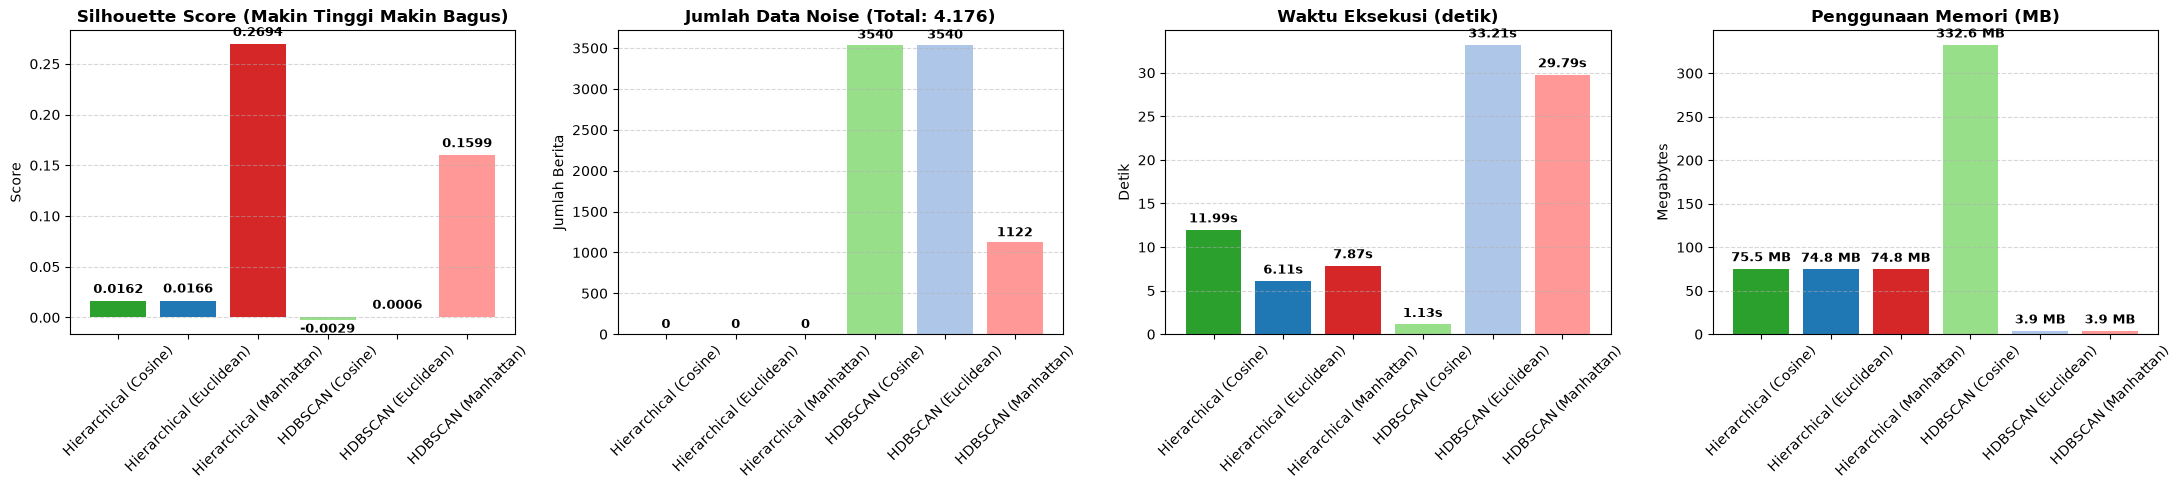

In [2]:
# Visualisasi Grafik Batang Perbandingan
label_model = df_perbandingan['Model'] + ' (' + df_perbandingan['Metrik Jarak'] + ')'

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
warna = ['#2ca02c', '#1f77b4', '#d62728', '#98df8a', '#aec7e8', '#ff9896']

# 1. Silhouette Score
bars1 = axes[0].bar(label_model, df_perbandingan['Silhouette Score'], color=warna)
axes[0].set_title('Silhouette Score (Makin Tinggi Makin Bagus)', fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, y + (0.005 if y >= 0 else -0.015), f'{y:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Noise Data
bars2 = axes[1].bar(label_model, df_perbandingan['Noise'], color=warna)
axes[1].set_title('Jumlah Data Noise (Total: 4.176)', fontweight='bold')
axes[1].set_ylabel('Jumlah Berita')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars2:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, y + 40, f'{int(y)}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Waktu Eksekusi
bars3 = axes[2].bar(label_model, df_perbandingan['Waktu Eksekusi (s)'], color=warna)
axes[2].set_title('Waktu Eksekusi (detik)', fontweight='bold')
axes[2].set_ylabel('Detik')
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars3:
    y = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2, y + 0.5, f'{y:.2f}s', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 4. Penggunaan Memori
bars4 = axes[3].bar(label_model, df_perbandingan['Memori (MB)'], color=warna)
axes[3].set_title('Penggunaan Memori (MB)', fontweight='bold')
axes[3].set_ylabel('Megabytes')
axes[3].tick_params(axis='x', rotation=45)
axes[3].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars4:
    y = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width() / 2, y + 5, f'{y:.1f} MB', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### 💡 Analisis Hasil Pengujian:

1. **Model Terbaik: Hierarchical Clustering (Manhattan)**
   - Meraih **Silhouette Score tertinggi (0.2694)** di antara seluruh model.
   - Berhasil mengelompokkan seluruh **4.176 artikel berita hoaks** ke dalam 6 klaster topik tanpa ada data yang terbuang (**Noise = 0**).
   - Metrik Manhattan (L1-norm) sangat cocok untuk teks TF-IDF berdimensi tinggi karena menghitung selisih frekuensi kata secara langsung tanpa mengkuadratkannya.

2. **Kelemahan HDBSCAN pada Data Teks (Density Drop)**
   - Pada metrik Cosine dan Euclidean, HDBSCAN membuang **3.540 berita (84.77%)** sebagai noise.
   - Hal ini disebabkan oleh *Curse of Dimensionality* pada matriks TF-IDF (1.000 dimensi yang sparse). Titik-titik data berada berjauhan sehingga algoritma berbasis densitas gagal mendeteksi kepadatan minimum.
   - Pada HDBSCAN Manhattan, noise turun menjadi 1.122 data dengan Silhouette 0.1599, kembali memperkuat bukti keunggulan metrik Manhattan.

3. **Efisiensi Waktu & Memori**
   - Hierarchical Clustering sangat cepat (6 - 12 detik) dan stabil dengan memori ~75 MB.
   - HDBSCAN Cosine memerlukan memori puncak cukup besar (~332 MB) karena dense graph, sementara HDBSCAN Euclidean & Manhattan sangat hemat memori (~3.9 MB) namun membutuhkan waktu ~30 detik.

4. **Kesimpulan Akhir untuk PBL / UTS**
   - **Hierarchical Clustering Manhattan** adalah pilihan terbaik untuk mengkategorikan seluruh korpus hoaks Indonesia ke dalam topik-topik tematik yang rapi dan terstruktur.
